In [1]:
import pandas as pd
url = "https://www.eia.gov/dnav/pet/hist_xls/WDISTUS1w.xls"
df = pd.read_excel(url, sheet_name="Data 1", skiprows=2)
df.tail()

/var/folders/41/2n5lc2ln757c3vkw3qzbvyv00000gn/T/ipykernel_14526/818602889.py:3: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  df = pd.read_excel(url, sheet_name="Data 1", skiprows=2)


,Date,Weekly U.S. Ending Stocks of Distillate Fuel Oil (Thousand Barrels)
2297,2026-10-09,102611
2298,2026-10-16,104286
2299,2026-10-23,102824
2300,2026-10-30,99259
2301,2026-11-06,103330


In [4]:
df.columns = ['Date', 'Stocks']
df['Date'] = pd.to_datetime(df['Date'])
print(df.dtypes)
df.tail()

Date      datetime64[us]
Stocks             int64
dtype: object


,Date,Stocks
2297,2026-10-09,102611
2298,2026-10-16,104286
2299,2026-10-23,102824
2300,2026-10-30,99259
2301,2026-11-06,103330


In [7]:
latest_date = df["Date"].iloc[-1]
latest = df["Stocks"].iloc[-1]
previous = df["Stocks"].iloc[-2]
change = latest - previous

if change > 0:
    direction = "increased"
else:
    direction = "decreased"

print(f"Week of {latest_date:%Y-%m-%d}: {latest/1000:.1f} M bbl, {direction} by {abs(change)/1000:.1f} M bbl from the previous week.")

Week of 2026-11-06: 103.3 M bbl, increased by 4.1 M bbl from the previous week.


In [10]:
df["year"] = df["Date"].dt.year
df["week"] = df["Date"].dt.isocalendar().week

latest_week = df["week"].iloc[-1]
latest_year = df["year"].iloc[-1]

past5_years = df[
    (df["week"] == latest_week)
    & (df["year"] >= latest_year - 5)
    & (df["year"] < latest_year)
]
print(past5_years)

avg5 = past5_years["Stocks"].mean()
diff_pct = (latest - avg5) / avg5 * 100

if diff_pct > 0:
    direction = "above"
else: 
    direction = "below"

print(f"5-year average for week {latest_week}: {avg5/1000:.1f} M bbl, {abs(diff_pct):.1f}% {direction} the average.")

           Date  Stocks  year  week
2041 2021-11-12  123685  2021    45
2093 2022-11-11  107383  2022    45
2145 2023-11-10  106579  2023    45
2197 2024-11-08  114415  2024    45
2249 2025-11-07  110909  2025    45
5-year average for week 45: 112.6 M bbl, 8.2% below the average.


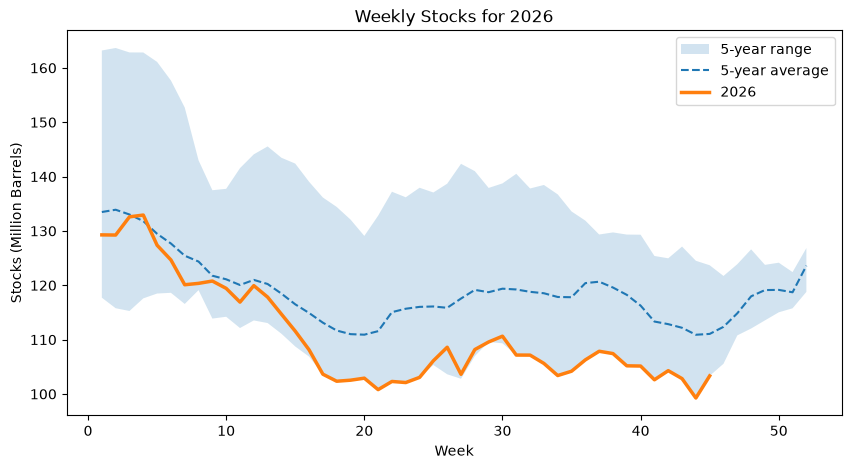

In [13]:
import os
import matplotlib.pyplot as plt

os.makedirs("output", exist_ok=True)

hist = df[
    (df["year"] >= latest_year - 5)
    & (df["year"] <= latest_year)
    & (df["week"] <=52)
]

stats = hist.groupby("week")["Stocks"].agg(["mean", "min", "max"])

this_year = df[df["year"] == latest_year]

plt.figure(figsize=(10, 5))

plt.fill_between(stats.index, stats["min"]/1000, stats["max"]/1000, alpha = 0.2, label="5-year range")

plt.plot(stats.index, stats["mean"]/1000, linestyle="--", label = "5-year average")
plt.plot(this_year["week"], this_year["Stocks"]/1000, linewidth = 2.5, label = str(latest_year))
plt.xlabel("Week")
plt.ylabel("Stocks (Million Barrels)")
plt.title(f"Weekly Stocks for {latest_year}")
plt.legend()
plt.savefig("output/weekly_stocks.png", dpi=300, bbox_inches='tight')
plt.show()